Случайная величина Y имеет экспоненциальное распределение, M[Y] = 2

○ Построить для нее функцию и плотность распределения вероятностей.
○ Вычислить вероятности P(Y < 3), P(Y > 2), P(1 < Y < 2.5).
○ Отобразить, вероятности на графиках функции и плотности вероятностей.
○ Проверить выполнение правила «3-сигм» для Y , отобразить это правило на графике
плотности вероятностей.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

mean = 2  #  M[Y]
lam = 1 / mean     # λ = 1 / M[Y]
dist = expon(scale=mean)   # scale = 1 / M[Y]

In [5]:
def exponential_distribution(mean, dist, probabilities=None, x_max=12, points=600):
    if probabilities is None:
        probabilities = [
            ('less', 3),
            ('more', 2),
            ('between', 1, 2.5)
        ]

    x = np.linspace(0, x_max, points)
    pdf_x = dist.pdf(x)
    cdf_x = dist.cdf(x)

    results = {}
    for p in probabilities:
        if p[0] == 'less':         # P(X < b)
            b = p[1]
            val = dist.cdf(b)
            results[f"P(X < {b})"] = val

        elif p[0] == 'more':       # P(X > a)
            a = p[1]
            val = 1 - dist.cdf(a)
            results[f"P(X > {a})"] = val

        elif p[0] == 'between':    # P(a < X < b)
            a, b = p[1], p[2]
            val = dist.cdf(b) - dist.cdf(a)
            results[f"P({a} < X < {b})"] = val

        else:
            raise ValueError("Unknown command for probabilities")

    # правило 3-сигм
    sigma = mean
    left_3 = max(0, mean - 3 * sigma)
    right_3 = mean + 3 * sigma

    return {
        "x": x,
        "pdf_x": pdf_x,
        "cdf_x": cdf_x,
        "results": results,
        "three_sigma_interval": (left_3, right_3),
        "mean": mean,
        "sigma": sigma
    }

In [ ]:
def plot_exponential(data):
    x, pdf_x, cdf_x = data["x"], data["pdf_x"], data["cdf_x"]
    left_3, right_3 = data["three_sigma_interval"]
    mean = data["mean"]
    probs = data["results"]

    prob_colors = {
        "less": "green",
        "more": "black",
        "between": "blue"
    }

    # PDF
    plt.figure(figsize=(10, 5))  # рабочая область
    plt.plot(x, pdf_x, label=f"PDF exp(mean={mean})")  # отображение кривой
    plt.locator_params(axis='x', nbins=15)

    # область правила трех сигм
    plt.axvspan(left_3, right_3, color='red', alpha=0.15, label="3σ область")

    # отображение вероятностей на PDF
    for key, value in probs.items():
        # P(X < b)
        if key.startswith("P(X <"):
            b = float(key.split("<")[1].rstrip(")"))
            mask = x < b
            plt.fill_between(x, pdf_x, where=mask, alpha=0.25,
                            color=prob_colors["less"], label=f"{key} = {value:.3f}")
        # P(X > a)
        elif key.startswith("P(X >"):
            a = float(key.split(">")[1].rstrip(")"))
            mask = x > a
            plt.fill_between(x, pdf_x, where=mask, alpha=0.25,
                            color=prob_colors["more"], label=f"{key} = {value:.3f}")
        # P(a < X < b)
        elif "< X <" in key:
            a, b = key.replace("P(", "").replace(")", "").split(" < X < ")
            a, b = float(a), float(b)
            mask = (x >= a) & (x <= b)
            plt.fill_between(x, pdf_x, where=mask, alpha=0.25,
                            color=prob_colors["between"], label=f"{key} = {value:.3f}")

    plt.title("Плотность распределения (PDF)")
    plt.legend()
    plt.grid()
    plt.show()


    # CDF
    plt.figure(figsize=(10, 5))
    plt.plot(x, cdf_x, label=f"CDF exp(mean={mean})")
    plt.locator_params(axis='x', nbins=15)

    # отображение вероятностей на CDF
    for key, value in probs.items():
        # P(X < b)
        if key.startswith("P(X <"):
            b = float(key.split("<")[1].rstrip(")"))
            y = expon(scale=mean).cdf(b)
            plt.axvline(b, ls="--", alpha=0.7)
            plt.scatter([b], [y], color="red")
            plt.text(b, y, f"{value:.3f}", va="bottom")
        # P(X > a)
        elif key.startswith("P(X >"):
            a = float(key.split(">")[1].rstrip(")"))
            y = expon(scale=mean).cdf(a)
            plt.axvline(a, ls="--", alpha=0.7)
            plt.scatter([a], [y], color="red")
            plt.text(a, y, f"{value:.3f}", va="bottom")
        # P(a < X < b)
        elif "< X <" in key:
            a, b = key.replace("P(", "").replace(")", "").split(" < X < ")
            a, b = float(a), float(b)
            y1 = expon(scale=mean).cdf(a)
            y2 = expon(scale=mean).cdf(b)

            plt.axvline(a, ls="--", alpha=0.7)
            plt.axvline(b, ls="--", alpha=0.7)
            plt.scatter([a], [y1], color="red")
            plt.scatter([b], [y2], color="red")
            plt.text(a, y1, f"{y1:.3f}", va="bottom")
            plt.text(b, y2, f"{y2:.3f}", va="bottom")

    plt.title("Функция распределения (CDF)")
    plt.legend()
    plt.grid()
    plt.show()

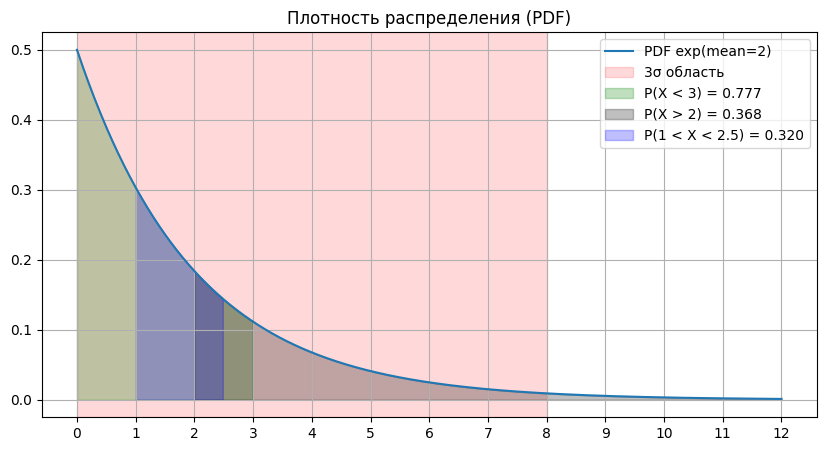

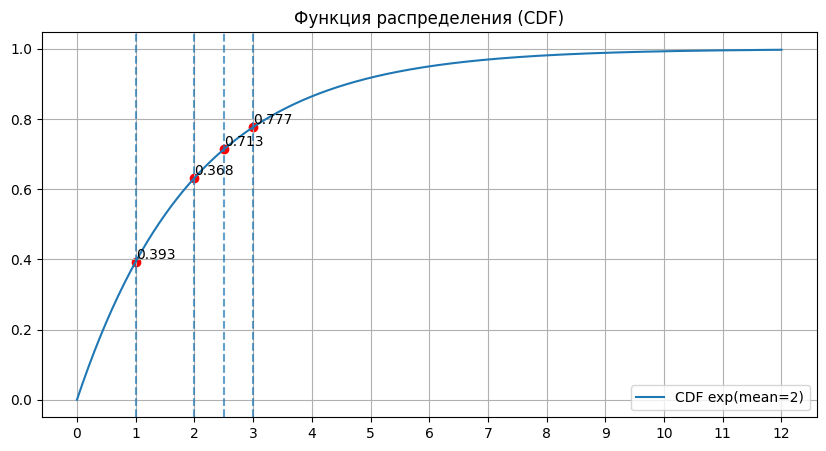

In [7]:
data = exponential_distribution(mean, dist)
plot_exponential(data)